In [42]:
import pandas as pd 
import numpy as np 
from sklearn.preprocessing import StandardScaler 
from sklearn.linear_model  import Ridge,Lasso,RidgeCV, LassoCV, ElasticNet, ElasticNetCV, LogisticRegression
from sklearn.model_selection import train_test_split
from statsmodels.stats.outliers_influence import variance_inflation_factor 
from sklearn.metrics import accuracy_score, confusion_matrix, roc_curve, roc_auc_score
import matplotlib.pyplot as plt
from pandas_profiling import ProfileReport
import seaborn as sns
import pickle

In [43]:
#Reading the data file

df = pd.read_csv("https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv")

In [44]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [45]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [46]:
#Generating the ProfileReport

ProfileReport(df)

In [47]:
df.columns

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')

In [48]:
df.dtypes

Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object

In [49]:
#Replacing the zero's values in the dataset with mean.

In [50]:
df['BMI']=df['BMI'].replace(0,df['BMI'].mean())

In [51]:
df['Insulin']=df['Insulin'].replace(0,df['Insulin'].mean())

In [52]:
df['SkinThickness']=df['SkinThickness'].replace(0,df['SkinThickness'].mean())


In [53]:
df['BloodPressure']=df['BloodPressure'].replace(0,df['BloodPressure'].mean())

In [54]:
df['Glucose']=df['Glucose'].replace(0,df['Glucose'].mean())

<AxesSubplot:>

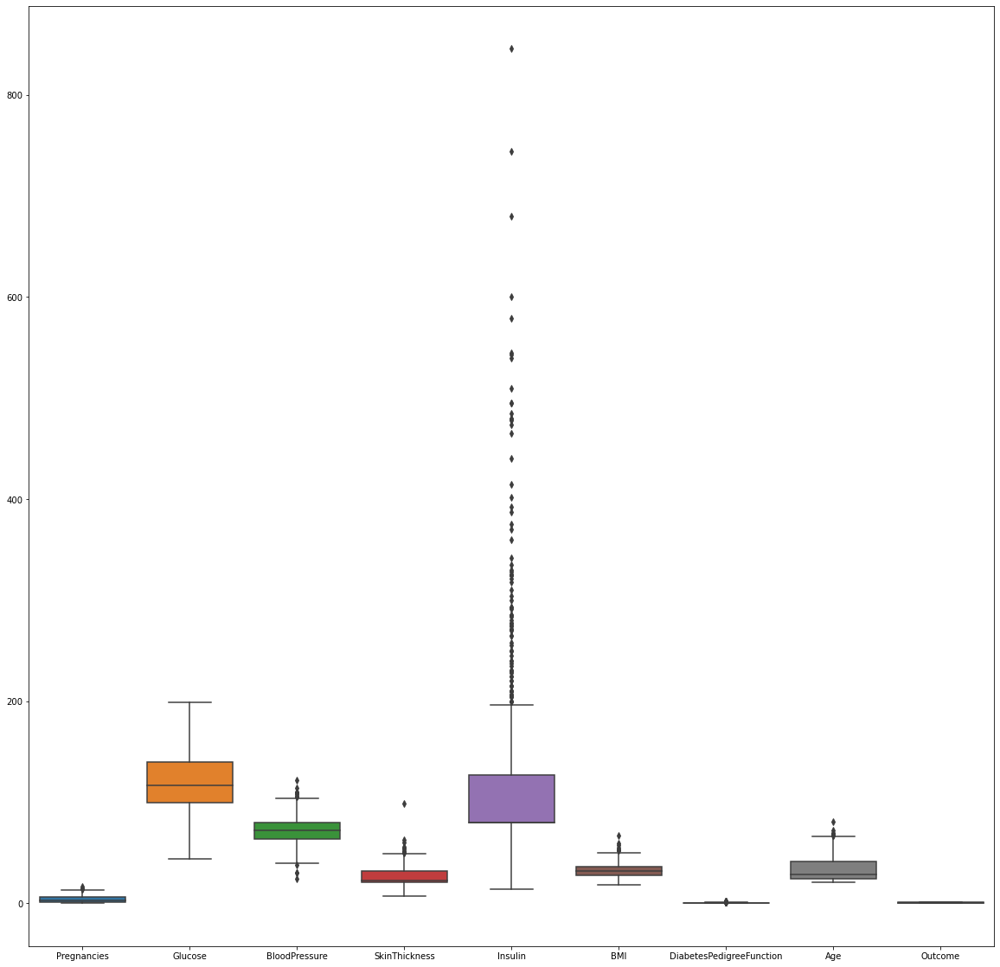

In [55]:
#finding outliers
fig,ax=plt.subplots(figsize=(20,20))
sns.boxplot(data=df,ax=ax)

In [56]:
q = df['Pregnancies'].quantile(.98)
df_new = df[df['Pregnancies'] < q]

q = df_new['BMI'].quantile(.99)
df_new = df_new[df_new['BMI']< q]

q = df_new['SkinThickness'].quantile(.99)
df_new = df_new[df_new['SkinThickness']< q]

q = df_new['Insulin'].quantile(.95)
df_new = df_new[df_new['Insulin']< q]

q = df_new['DiabetesPedigreeFunction'].quantile(.99)
df_new = df_new[df_new['DiabetesPedigreeFunction']< q]


q = df_new['Age'].quantile(.99)
df_new = df_new[df_new['Age']< q]

In [32]:
def outlier_removal(data):
        def outlier_limits(col):
            Q3, Q1 = np.nanpercentile(col, [75,25])
            IQR= Q3-Q1
            UL= Q3+1.5*IQR
            LL= Q1-1.5*IQR
            return UL, LL

        for column in data.columns:
            if data[column].dtype != 'int64':
                UL, LL= outlier_limits(data[column])
                data[column]= np.where((data[column] > UL) | (data[column] < LL), np.nan, data[column])

        return data
df_new=outlier_removal(df)        

<AxesSubplot:>

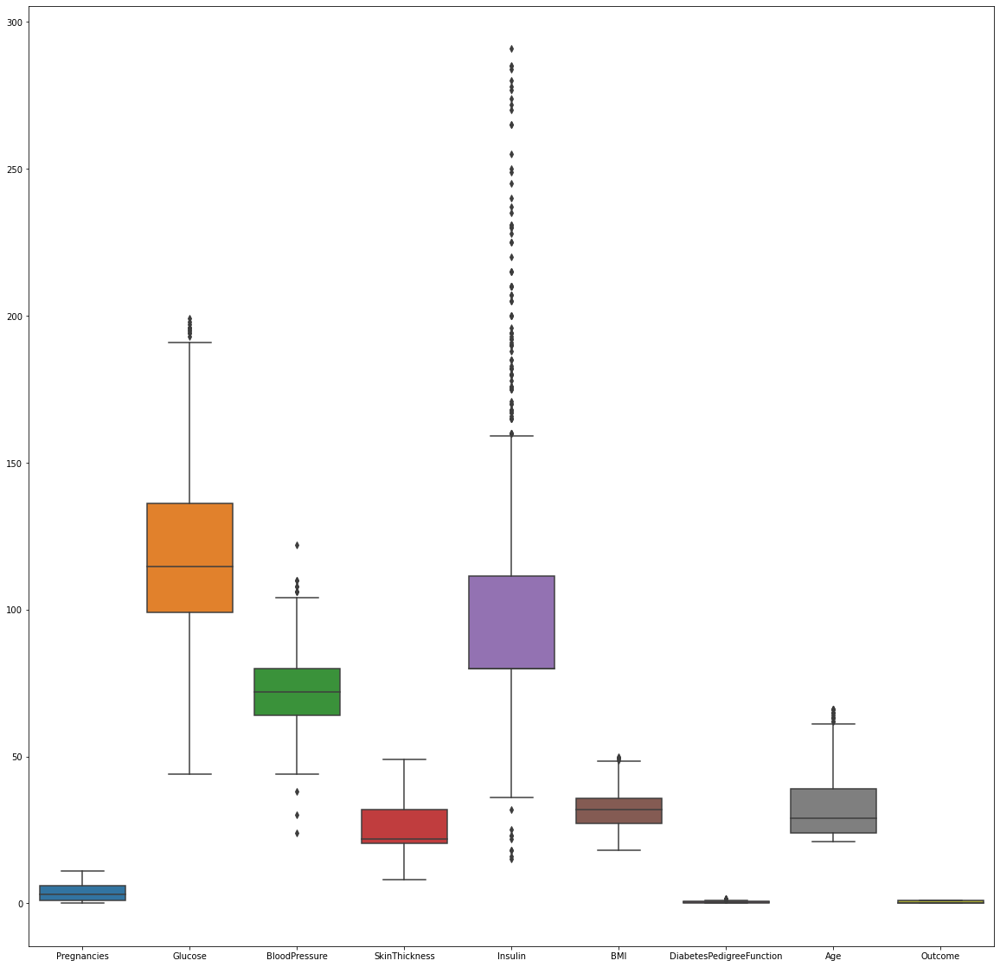

In [57]:
fig,ax=plt.subplots(figsize=(20,20))
sns.boxplot(data=df_new,ax=ax)

In [58]:
df_new.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,674.000000,674.000000,674.000000,674.000000,674.000000,674.000000,674.000000,674.000000,674.000000
mean,3.602374,119.217318,71.994622,25.721354,101.061453,31.904204,0.447338,32.454006,0.327893
std,3.011478,29.272890,11.891728,8.507237,49.005425,6.384238,0.285170,10.964692,0.469794
min,0.000000,44.000000,24.000000,8.000000,15.000000,18.200000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,64.000000,20.536458,79.799479,27.300000,0.238000,24.000000,0.000000
50%,3.000000,114.500000,72.000000,22.000000,79.799479,31.992578,0.356000,29.000000,0.000000
75%,6.000000,136.000000,80.000000,32.000000,111.500000,35.800000,0.600000,39.000000,1.000000
max,11.000000,199.000000,122.000000,49.000000,291.000000,50.000000,1.476000,66.000000,1.000000


In [59]:
ProfileReport(df_new)

In [61]:
y=df_new['Outcome']

In [62]:
x=df_new.drop(columns=['Outcome'])

In [64]:
scalar = StandardScaler()
ProfileReport(pd.DataFrame(scalar.fit_transform(x)))
X_scaled = scalar.fit_transform(x)

<AxesSubplot:>

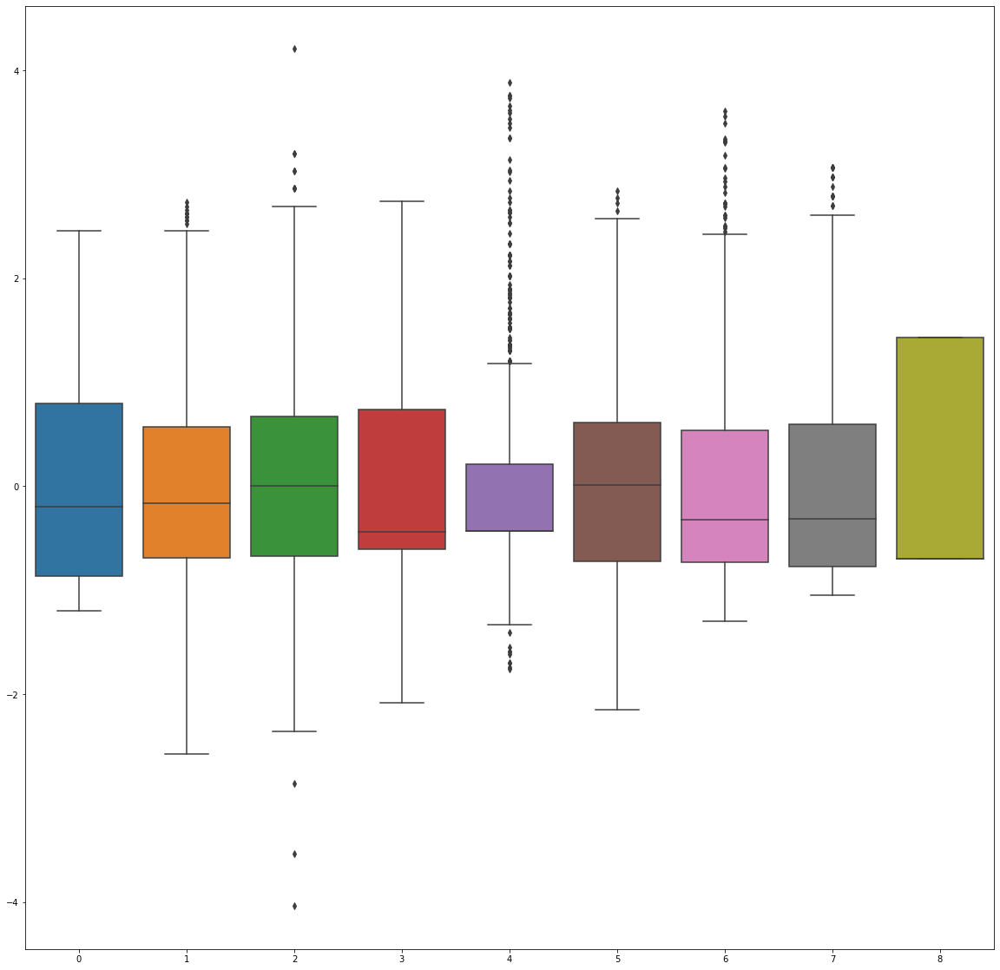

In [65]:
df_new_scalar = pd.DataFrame(scalar.fit_transform(df_new))
fig ,ax  = plt.subplots(figsize = (20,20))
sns.boxplot(data = df_new_scalar , ax = ax)

In [66]:
#Finding multicollinearity

def vif_score(x):
    scaler = StandardScaler()
    arr = scaler.fit_transform(x)
    return pd.DataFrame([[x.columns[i], variance_inflation_factor(arr,i)] for i in range(arr.shape[1])], columns=["FEATURE", "VIF_SCORE"])

In [67]:
vif_score(x)

,FEATURE,VIF_SCORE
0,Pregnancies,1.449056
1,Glucose,1.304263
2,BloodPressure,1.262686
3,SkinThickness,1.470049
4,Insulin,1.271017
5,BMI,1.513160
6,DiabetesPedigreeFunction,1.042300
7,Age,1.662728


In [68]:
x_train, x_test, y_train, y_test = train_test_split(X_scaled , y , test_size = .20 , random_state = 144)

In [69]:
x_train

array([[-0.86479354,  0.19769063, -1.85094678, ...,  0.21879402,
         1.80609569, -0.40651517],
       [ 2.45830136,  1.22329076,  0.33707068, ...,  0.21879402,
         3.1782269 ,  1.69268475],
       [ 0.13213493,  0.91561072,  1.09446134, ..., -0.47091521,
        -0.90658316, -0.49778473],
       ...,
       [-0.86479354, -0.28092276,  1.17861586, ..., -0.28281269,
        -1.06801036, -0.86286298],
       [ 1.46137289,  0.02675728,  0.50537972, ..., -1.08224839,
        -0.13454002,  2.87918905],
       [-0.86479354, -0.75953616, -0.33616546, ..., -0.73739378,
         2.27283086, -0.95413254]])

In [70]:
x_test

array([[ 1.32134931e-01, -1.44176079e-01,  4.52611463e-04, ...,
        -4.70915211e-01, -2.50346495e-01,  1.23633694e+00],
       [-1.19710303e+00,  6.76304024e-01, -8.41092564e-01, ...,
        -1.53682948e+00, -8.43415997e-01, -1.04540210e+00],
       [ 2.45830136e+00,  8.13050708e-01,  1.85185200e+00, ...,
         7.36075942e-01, -6.78479508e-01,  1.69268475e+00],
       ...,
       [ 7.96753910e-01, -5.54416131e-01, -5.04474494e-01, ...,
        -1.19197486e+00, -6.96025943e-01, -3.15245608e-01],
       [-5.32484049e-01, -1.20396288e+00, -2.43135269e-01, ...,
         1.38528976e-02, -5.03015158e-01, -1.04540210e+00],
       [-8.64793539e-01, -1.64838960e+00, -2.01925581e+00, ...,
        -1.80330804e+00, -4.36338705e-01, -9.54132539e-01]])

In [72]:
y_test

406    1
511    0
24     1
751    0
689    1
      ..
3      0
469    0
587    0
60     0
97     0
Name: Outcome, Length: 135, dtype: int64

In [73]:
logr = LogisticRegression(verbose=1)

In [74]:
logr.fit(x_train,y_train)

[Parallel(n_jobs=1)]: Using backend SequentialBackend with 1 concurrent workers.
[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    1.7s finished


LogisticRegression(verbose=1)

In [75]:
x_test[0]

array([ 1.32134931e-01, -1.44176079e-01,  4.52611463e-04, -6.09921498e-01,
       -4.34192020e-01, -4.70915211e-01, -2.50346495e-01,  1.23633694e+00])

In [77]:
logr.predict([x_test[0]])

array([0], dtype=int64)

In [78]:
logr.predict_proba([x_test[0]])

array([[0.83549024, 0.16450976]])

In [79]:
logr.predict_log_proba([x_test[0]])

array([[-0.17973662, -1.80478536]])

In [80]:
logr_liblinear = LogisticRegression(verbose=1,solver='liblinear')

In [81]:
logr_liblinear.fit(x_train,y_train )

[LibLinear]

LogisticRegression(solver='liblinear', verbose=1)

In [82]:
y_pred_liblinear = logr_liblinear.predict(x_test)

In [83]:
y_pred_default = logr.predict(x_test)

In [84]:
confusion_matrix(y_test,y_pred_liblinear)

array([[77, 10],
       [24, 24]], dtype=int64)

In [85]:
confusion_matrix(y_test,y_pred_default)

array([[77, 10],
       [24, 24]], dtype=int64)

In [86]:
#Model Evaluation

def model_eval(y_true,y_pred):
    tn, fp, fn, tp = confusion_matrix(y_test,y_pred).ravel()
    accuracy=(tp+tn)/(tp+tn+fp+fn)
    precision=tp/(tp+fp)
    recall=tp/(tp+fn)
    specificity=tn/(fp+tn)
    F1_Score = 2*(recall * precision) / (recall + precision)
    result={"Accuracy":accuracy,"Precision":precision,"Recall":recall,'Specficity':specificity,'F1':F1_Score}
    return result
model_eval(y_test,y_pred_liblinear)

{'Accuracy': 0.7481481481481481,
 'Precision': 0.7058823529411765,
 'Recall': 0.5,
 'Specficity': 0.8850574712643678,
 'F1': 0.5853658536585366}

In [87]:
auc = roc_auc_score(y_test,y_pred_liblinear)

In [88]:
auc

0.692528735632184

In [89]:
fpr, tpr, thresholds  = roc_curve(y_test,y_pred_liblinear)

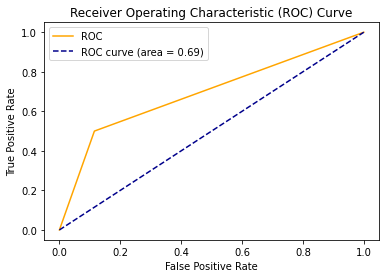

In [90]:
plt.plot(fpr, tpr, color='orange', label='ROC')
plt.plot([0, 1], [0, 1], color='darkblue', linestyle='--',label='ROC curve (area = %0.2f)' % auc)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend()
plt.show()

In [98]:
x=lambda a,b:a+b

In [99]:
x(10,2)

12

In [100]:
def myfun(a):
    return lambda b:b*a

In [102]:
y=myfun(2)

In [103]:
y(11)

22